# Chapter-14: Human-In-The-Loop, Time Travel & Streaming

# <font color="#800000">Implementing Human-In-The-Loop</font>

## <font color="#3366FF">Implementing Human-In-The-Loop</font>

### Example of Human-In-The-Loop

#### Setup

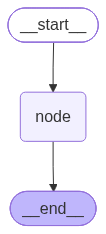

In [1]:
import uuid
from typing import Optional
from typing_extensions import TypedDict
from IPython.display import Image, display
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.constants import START
from langgraph.graph import StateGraph
from langgraph.types import interrupt, Command

## State Schema
class State(TypedDict):
    input: str
    output: Optional[str]

## Node Function
def node(state: State):
    print("Node execution started..")

    ## Interrupt the node execution
    human_value = interrupt("Please tell me your name to continue.")

    print("Node execution ends, returning state value..")
    return {"output": "Hello "+ human_value}

## Create a single node graph
builder = StateGraph(State)
builder.add_node("node", node)
builder.add_edge(START, "node")

## Compile graph with InMemorysaver
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))


#### Invoke Graph

In [2]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Invoke graph
response = graph.invoke({"input": "Hello"}, config)

## Print Response
print(response)


Node execution started..
{'input': 'Hello', '__interrupt__': [Interrupt(value='Please tell me your name to continue.', id='fb9ea43b489675f7b3f0e381e2eef0dd')]}


In [3]:
## Invoke Graph with Command with value to resume node execution 
response = graph.invoke(Command(resume="Peter"), config)

## Print Response    
print(response)


Node execution started..
Node execution ends, returning state value..
{'input': 'Hello', 'output': 'Hello Peter'}


## <font color="#3366FF">Common Use Cases of Human-In-The-Loop</font>

### Example

#### Setup

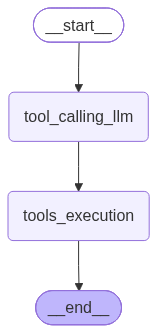

In [4]:
import os
import uuid
from dotenv import load_dotenv
from typing import TypedDict
from langchain.tools import tool
from langchain_openai import ChatOpenAI
from IPython.display import Image, display
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END, MessagesState
from langchain.messages import HumanMessage
from langgraph.types import Command, interrupt


## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')


## Tool Function
@tool
def buy_stock(name: str, qty: int) -> str:
    """This function buys a specific quantity of a stock."""

    ## Interrupt to confirm buy request
    user_response = interrupt({
        "stock": name,
        "quantity": qty,
        "action": "buy",
        "message": f"Please confirm purchase of {qty} stocks of {name} (yes/no):",
    })

    ## If user approves, proceed with purchase; else cancel
    if user_response.get("approval").lower() == "yes":

        ## Retrieve modified qty or use original qty
        qty = user_response.get("modified_qty",qty)

        ## Return successful purchase confirmation
        return f"Successfully purchased {qty} shares of {name}."
    else:
        ## Return purchase cancellation confirmation
        return f"Cancelled purchase of {qty} shares of {name}."

## Create tools list
tools = [buy_stock]

## Define OpenAI Chat Model and bind with Tools
llm = ChatOpenAI(model="gpt-5-mini").bind_tools(tools)

## Define Node with Tool Calling LLM
def tool_calling_llm(state: MessagesState):

    result = llm.invoke(state["messages"])
    return {"messages": state["messages"] + [result]}

## Create Graph
graph_builder = StateGraph(MessagesState)
graph_builder.add_node("tool_calling_llm", tool_calling_llm)
graph_builder.add_node("tools_execution", ToolNode(tools))
graph_builder.add_edge(START, "tool_calling_llm")
graph_builder.add_edge("tool_calling_llm", "tools_execution")
graph_builder.add_edge("tools_execution", END)

## Compile Graph with InMemorySaver Checkpointer
checkpointer = InMemorySaver()
graph = graph_builder.compile(checkpointer=checkpointer)

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))


#### Invoke Graph

In [5]:
## Create config with thread ID
config = {"configurable": {"thread_id":uuid.uuid4()}}

## Invoke Graph
response = graph.invoke({"messages": HumanMessage(content="Buy 19 shares of Microsoft.")},config)

## Print Messages
for m in response['messages']:
    m.pretty_print()

## Print Interrupt Details (We expect this)
print(response["__interrupt__"])


================================ Human Message =================================

Buy 19 shares of Microsoft.
================================== Ai Message ==================================
Tool Calls:
  buy_stock (call_2H640I9cQWRWQtR073z3N3Xd)
 Call ID: call_2H640I9cQWRWQtR073z3N3Xd
  Args:
    name: Microsoft
    qty: 19
[Interrupt(value={'stock': 'Microsoft', 'quantity': 19, 'action': 'buy', 'message': 'Please confirm purchase of 19 stocks of Microsoft (yes/no):'}, id='e9ef4e4ac099e20ffa1251e16cd93cae')]


#### Resume Execution With Approval

In [7]:
## Resume Graph with approval as "yes"
response = graph.invoke(Command(resume={"approval": "yes"}),config=config)

## Print Messages
response["messages"][-1].pretty_print()


================================= Tool Message =================================
Name: buy_stock

Successfully purchased 19 shares of Microsoft.


#### Resume Execution With Modifications.

In [8]:
## Create config with thread ID
config = {"configurable": {"thread_id":uuid.uuid4()}}

## Invoke Graph
response = graph.invoke({"messages": HumanMessage(content="Buy 19 shares of Microsoft.")},config)

## Print Messages
for m in response['messages']:
    m.pretty_print()

## Print Interrupt Details (We expect this)
print(response["__interrupt__"])

### ----------- Resume Block ----------------------

## Resume Graph with approval as "yes" and modified qty as 25
response = graph.invoke(Command(resume={"approval": "yes", "modified_qty": 25}),config=config)



================================ Human Message =================================

Buy 19 shares of Microsoft.
================================== Ai Message ==================================
Tool Calls:
  buy_stock (call_K2zxz2j5kiNXv2rv3H1gl5hj)
 Call ID: call_K2zxz2j5kiNXv2rv3H1gl5hj
  Args:
    name: Microsoft
    qty: 19
[Interrupt(value={'stock': 'Microsoft', 'quantity': 19, 'action': 'buy', 'message': 'Please confirm purchase of 19 stocks of Microsoft (yes/no):'}, id='90fa458164b541041a407ea06a4b5ea7')]


In [9]:
## Print Messages
response["messages"][-1].pretty_print()


================================= Tool Message =================================
Name: buy_stock

Successfully purchased 25 shares of Microsoft.


# <font color="#800000">Time Travel</font>

## <font color="#3366FF">Performing Time Travel</font>

### Example of Time Travel

#### Setup

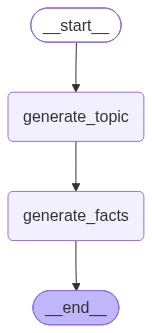

In [11]:
import os
import uuid
from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_openai import ChatOpenAI
from typing_extensions import TypedDict, NotRequired
from langgraph.graph import StateGraph, START, END
from langchain.chat_models import init_chat_model
from langgraph.checkpoint.memory import InMemorySaver

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Initialize ChatOpenAI LLM
llm = ChatOpenAI(model="gpt-5-mini")

## State Schema
class State(TypedDict):
    topic: NotRequired[str]
    fact: NotRequired[str]

## Node Function 1
def generate_topic(state: State):
    ## Invoke LLM to generate a random topic
    output = llm.invoke("Give me a random topic for a fact. Reply with just one word")
    return {"topic": output.content}

## Node Function 2
def generate_facts(state: State):
    ## Invoke LLM to generate a fact for the given topic on the topic
    output = llm.invoke(f"Write a one line fact about {state['topic']}")
    return {"fact": output.content}

## Create Graph
graph_builder = StateGraph(State)
graph_builder.add_node("generate_topic", generate_topic)
graph_builder.add_node("generate_facts", generate_facts)
graph_builder.add_edge(START, "generate_topic")
graph_builder.add_edge("generate_topic", "generate_facts")
graph_builder.add_edge("generate_facts", END)

## Compile graph with InMemorySaver checkpointer
checkpointer = InMemorySaver()
graph = graph_builder.compile(checkpointer=checkpointer)

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))


#### Invoke Graph

In [12]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Invoke Graph
graph.invoke({}, config)


{'topic': 'octopus', 'fact': 'An octopus has three hearts and blue blood.'}

#### Get State History

In [13]:
## Fetch State History as List
states = list(graph.get_state_history(config))

## Print State Configurations
for state in states:
    print(state.next)
    print(state.config)
    print("\n")


()
{'configurable': {'thread_id': '8e6205ff-048a-4440-acc6-514ddf284b4a', 'checkpoint_ns': '', 'checkpoint_id': '1f1c80ff-5afd-6b9a-8002-f4d2be2ffa4b'}}


('generate_facts',)
{'configurable': {'thread_id': '8e6205ff-048a-4440-acc6-514ddf284b4a', 'checkpoint_ns': '', 'checkpoint_id': '1f1c80ff-44d6-69b6-8001-f61798fe6d3c'}}


('generate_topic',)
{'configurable': {'thread_id': '8e6205ff-048a-4440-acc6-514ddf284b4a', 'checkpoint_ns': '', 'checkpoint_id': '1f1c80ff-2ff6-67f8-8000-74cd0a38acdb'}}


('__start__',)
{'configurable': {'thread_id': '8e6205ff-048a-4440-acc6-514ddf284b4a', 'checkpoint_ns': '', 'checkpoint_id': '1f1c80ff-2feb-63da-bfff-7c185148e212'}}




#### Identify State

In [14]:
## Identify the state to update
identified_state = states[1]

## Print details to confirm 
print(identified_state.next)
print(identified_state.values)
print(identified_state.config)


('generate_facts',)
{'topic': 'octopus'}
{'configurable': {'thread_id': '8e6205ff-048a-4440-acc6-514ddf284b4a', 'checkpoint_ns': '', 'checkpoint_id': '1f1c80ff-44d6-69b6-8001-f61798fe6d3c'}}


#### Scenario 1: Re-Execute Without Updates

In [15]:
## Re-execute graph from identified checkpoint
graph.invoke(None, identified_state.config)


{'topic': 'octopus',
 'fact': 'Octopuses have three hearts and blue, copper-rich blood.'}

#### Scenario 2: Re-Execute With State Updates

In [16]:
## Update State
new_config = graph.update_state(identified_state.config, values={"topic": "Mars"})
print(new_config)

## Resume graph from new checkpoint
graph.invoke(None, new_config)


{'configurable': {'thread_id': '8e6205ff-048a-4440-acc6-514ddf284b4a', 'checkpoint_ns': '', 'checkpoint_id': '1f1c8105-5997-650c-8002-bbd322b7b093'}}


{'topic': 'Mars',
 'fact': 'Mars hosts the largest volcano in the solar system, Olympus Mons, which rises about 22 km (13.6 mi) above the surrounding plains.'}

# <font color="#800000">Streaming</font>

## <font color="#3366FF">Example Of Streaming Modes</font>

### Set Up For Example

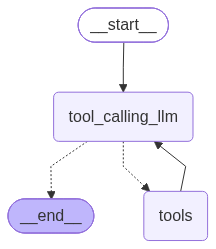

In [18]:
import os
import uuid
import random
from dotenv import load_dotenv
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.graph import MessagesState
from langchain.messages import HumanMessage
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langchain.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.config import get_stream_writer

## Loading OpenAI API from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Initialize ChatOpenAI LLM
llm = ChatOpenAI(model="gpt-5-mini")

@tool
def stock_price(name: str) -> int:
    """ Fetches the current market price of a stock."""
    
    ## Initialize Stream Writer
    writer = get_stream_writer() 

    ## Stream custom data
    writer(f"Connecting to stock exchange server..")
    writer(f"Retrieving stock price of : {name}..")

    price = round(random.uniform(10, 500), 2)
    return price

## Create Tool List
tool_list = [stock_price]

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tool_list)
    
## Tool Calling Node
def tool_calling_llm(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Initialize StateGraph with MessagesState
graph_builder = StateGraph(MessagesState)

## Add Node to StateGraph
graph_builder.add_node("tool_calling_llm", tool_calling_llm)
graph_builder.add_node("tools", ToolNode(tool_list))

## Add Edges to StateGraph
graph_builder.add_edge(START, "tool_calling_llm")
graph_builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition,
)
graph_builder.add_edge("tools", "tool_calling_llm")

## Compile Graph
graph = graph_builder.compile(checkpointer=InMemorySaver())

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))


### Example Of Value Mode

In [19]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Stream graph
for chunk in graph.stream({"messages": [HumanMessage(content="What is current stock price of Tesla?")]}, 
                          stream_mode="values", 
                          config=config):
    print("\n",chunk)



 {'messages': [HumanMessage(content='What is current stock price of Tesla?', additional_kwargs={}, response_metadata={}, id='0bba087d-0898-420a-84ce-51a041dedf0e')]}

 {'messages': [HumanMessage(content='What is current stock price of Tesla?', additional_kwargs={}, response_metadata={}, id='0bba087d-0898-420a-84ce-51a041dedf0e'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 88, 'prompt_tokens': 136, 'total_tokens': 224, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EZ0EqNRMPqCJYnfA9qOizPO6l6BoO', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a13c2f-6a95-7d12-92cc-83747f365bcf-0', tool_calls=[{'name': 'sto

In [20]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Stream graph
for chunk in graph.stream({"messages": [HumanMessage(content="What is current stock price of Tesla?")]}, 
                          stream_mode="updates", 
                          config=config):
    print("\n",chunk)



 {'tool_calling_llm': {'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 88, 'prompt_tokens': 136, 'total_tokens': 224, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EZ0FjJ5qF5rvVLJvX3umyQCpJvl4f', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a13c30-443b-75e3-9e5c-b37659128083-0', tool_calls=[{'name': 'stock_price', 'args': {'name': 'TSLA'}, 'id': 'call_EnozqrAtTyiiavhXtJBqB3BN', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 136, 'output_tokens': 88, 'total_tokens': 224, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'rea

#### Print Step & Content

In [21]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Stream graph
for chunk in graph.stream({"messages": [HumanMessage(content="What is current stock price of Tesla?")]}, 
                          stream_mode="updates",
                          config=config):
    for step, data in chunk.items():
        print(f"\nstep: {step}")
        print(f"content: {data['messages'][-1].content_blocks}")



step: tool_calling_llm
content: [{'type': 'tool_call', 'name': 'stock_price', 'args': {'name': 'TSLA'}, 'id': 'call_2Q7zSQZVZMkcyPjIK2OLJyhv'}]

step: tools
content: [{'type': 'text', 'text': '51.46'}]

step: tool_calling_llm
content: [{'type': 'text', 'text': 'The current market price for Tesla (TSLA) is $51.46 per share. \n\nWould you like recent intraday moves, a historical chart, news, or alerts for a target price?'}]


### Example Of Messages Mode

In [ ]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Stream graph
for chunk in graph.stream({"messages": [HumanMessage(content="What is current stock price of Tesla?")]}, 
                          stream_mode="messages", 
                          config=config):
    print("\n",chunk)


#### Print Only Content

In [23]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Stream Graph
for token, metadata in graph.stream({"messages": [HumanMessage(content="What is current stock price of Tesla?")]}, 
                                    stream_mode="messages",
                                    config=config):
    if token.content:  # Check if there's actual content
        if metadata['langgraph_node'] != 'tools': # Make sure its not tools call content
            print(token.content, end="", flush=True)  # Print token


The current market price of Tesla (TSLA) is $359.06.

### Example Of Custom Mode

In [24]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Stream graph
for chunk in graph.stream({"messages": [HumanMessage(content="What is current stock price of Tesla?")]}, 
                          stream_mode="custom", 
                          config=config):
    print(chunk)


Connecting to stock exchange server..
Retrieving stock price of : TSLA..


### Example Of Checkpoints Mode

In [25]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Stream graph
for chunk in graph.stream({"messages": [HumanMessage(content="What is current stock price of Tesla?")]}, 
                          stream_mode="checkpoints", 
                          config=config):
    print("\n",chunk)



 {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'adeaeb4f-3216-4936-af1f-354b880f33e4', 'checkpoint_id': '1f1c811e-befc-6334-bfff-85d59d4cb7a6'}}, 'parent_config': None, 'values': {'messages': []}, 'metadata': {'source': 'input', 'step': -1, 'parents': {}}, 'next': ['__start__'], 'tasks': [{'id': 'c2fcd957-0395-6a00-ce8e-c302869f5048', 'name': '__start__', 'interrupts': (), 'state': None}]}

 {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'adeaeb4f-3216-4936-af1f-354b880f33e4', 'checkpoint_id': '1f1c811e-bf17-6b3e-8000-db447a81416a'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'adeaeb4f-3216-4936-af1f-354b880f33e4', 'checkpoint_id': '1f1c811e-befc-6334-bfff-85d59d4cb7a6'}}, 'values': {'messages': [HumanMessage(content='What is current stock price of Tesla?', additional_kwargs={}, response_metadata={}, id='9a3ed9b1-0507-4dca-b88d-5f87d6a03470')]}, 'metadata': {'source': 'loop', 'step': 0, 'parents': {}}, 'next': ['tool_calling_

### Example Of Tasks Mode

In [26]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Stream agent
for chunk in graph.stream({"messages": [HumanMessage(content="What is current stock price of Tesla?")]}, 
                          stream_mode="tasks", 
                          config=config):
    print("\n",chunk)



 {'id': '3cf86102-b32f-7874-e76b-7056025cc2eb', 'name': 'tool_calling_llm', 'input': {'messages': [HumanMessage(content='What is current stock price of Tesla?', additional_kwargs={}, response_metadata={}, id='ff05d5ce-6f1a-40c0-ae05-dc9cb8eb6fac')]}, 'triggers': ('branch:to:tool_calling_llm',)}

 {'id': '3cf86102-b32f-7874-e76b-7056025cc2eb', 'name': 'tool_calling_llm', 'error': None, 'result': {'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 88, 'prompt_tokens': 136, 'total_tokens': 224, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EZ0LVxLfkxHzeeR6ynXNbiWQKf5dD', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}

### Example Of Debug Mode

In [27]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Stream agent
for chunk in graph.stream({"messages": [HumanMessage(content="What is current stock price of Tesla?")]}, 
                          stream_mode="debug", 
                          config=config):
    print("\n",chunk)



 {'step': -1, 'timestamp': '2026-10-14T20:59:36.416471+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': '6fd41430-d8e2-4c42-8e99-f99b5b6270ba', 'checkpoint_id': '1f1c8122-9f4e-69c0-bfff-76844bfc7b58'}}, 'parent_config': None, 'values': {'messages': []}, 'metadata': {'source': 'input', 'step': -1, 'parents': {}}, 'next': ['__start__'], 'tasks': [{'id': '1e122a18-e1e3-d491-9329-4ea3d202fe8c', 'name': '__start__', 'interrupts': (), 'state': None}]}}

 {'step': 0, 'timestamp': '2026-10-14T20:59:36.419272+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': '6fd41430-d8e2-4c42-8e99-f99b5b6270ba', 'checkpoint_id': '1f1c8122-9f69-6e1e-8000-8320aebbb576'}}, 'parent_config': {'configurable': {'checkpoint_ns': '', 'thread_id': '6fd41430-d8e2-4c42-8e99-f99b5b6270ba', 'checkpoint_id': '1f1c8122-9f4e-69c0-bfff-76844bfc7b58'}}, 'values': {'messages': [HumanMessage(content='What is current stock

### Example Of Multiple Streaming Modes

In [28]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Stream graph in both updates and custom modes.
for stream_mode, chunk in graph.stream(  
    {"messages": [HumanMessage(content="What is stock price of Tesla")]},
    stream_mode=["updates", "custom"],
    config=config
):
    print(f"stream_mode: {stream_mode}")
    if stream_mode == 'updates':
        for step, data in chunk.items():
            print(f"step: {step}")
            print(f"content: {data['messages'][-1].content_blocks}")
    else:
        print(f"content: {chunk}")
    print("\n")


stream_mode: updates
step: tool_calling_llm
content: [{'type': 'tool_call', 'name': 'stock_price', 'args': {'name': 'TSLA'}, 'id': 'call_5zDF6DmosmfPzOMzsp79WeCT'}]


stream_mode: custom
content: Connecting to stock exchange server..


stream_mode: custom
content: Retrieving stock price of : TSLA..


stream_mode: updates
step: tools
content: [{'type': 'text', 'text': '300.51'}]


stream_mode: updates
step: tool_calling_llm
content: [{'type': 'text', 'text': 'The current market price for Tesla (TSLA) is $300.51 (USD).\n\nNote: Market prices fluctuate in real time. Would you like the intraday change, percent change, a recent chart, or the price in another currency?'}]




### Example Of Async Stream Method

In [29]:
## Create config with thread ID
config = {"configurable": {"thread_id": uuid.uuid4()}}

## Stream Graph Asynchronously
async for token, metadata in graph.astream({"messages": [HumanMessage(content="What is current stock price of Tesla?")]}, 
                                    stream_mode="messages",
                                    config=config):
    if token.content:  # Check if there's actual content
        if metadata['langgraph_node'] != 'tools': # Make sure its not tools call content
            print(token.content, end="", flush=True)  # Print token


I fetched a quote for Tesla (TSLA): $21.36 per share (latest I could retrieve just now). Market prices change rapidly — would you like the price change, percent change, or a live update/graph?